# Partie 4 – Analyse de corrélation

Objectif : analyser les corrélations entre différentes variables métier de ClassicModels pour identifier des relations significatives.

Variables à analyser :
- **Prix produit vs quantité vendue** : est-ce que les produits chers se vendent moins ?
- **Délai de livraison vs satisfaction estimée** : est-ce que les délais longs impactent la satisfaction client (mesurée par l'évolution du comportement d'achat : panier moyen et fréquence) ?
- **Montant commande vs nombre de produits** : relation entre panier moyen et diversité
- **Ancienneté client vs montant total dépensé** : les anciens clients dépensent-ils plus ?
- **Prix achat vs prix vente** : analyse de la marge (MSRP vs buyPrice)
- **Nombre de commandes client vs montant total** : fidélité vs valeur client

In [23]:
import sys
from pathlib import Path

PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.database.connection import fetch_dataframe

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

## Extraction des données pour l'analyse de corrélation

On va extraire plusieurs variables depuis la base de données pour analyser leurs corrélations.

In [25]:
# Requête pour extraire les variables d'intérêt
query_correlation = """
SELECT
    -- Variables produit
    p.productCode,
    p.buyPrice AS prix_achat,
    p.MSRP AS prix_vente,
    
    -- Variables vente
    od.quantityOrdered AS quantite_vendue,
    od.priceEach AS prix_unitaire_vendu,
    (od.quantityOrdered * od.priceEach) AS montant_ligne,
    
    -- Variables commande
    o.orderNumber,
    o.orderDate,
    o.requiredDate,
    o.shippedDate,
    o.status,
    DATEDIFF(o.shippedDate, o.orderDate) AS delai_livraison_jours,
    DATEDIFF(o.shippedDate, o.requiredDate) AS delai_vs_requis_jours,
    
    -- Variables client
    c.customerNumber,
    c.customerName,
    DATEDIFF(o.orderDate, (SELECT MIN(o2.orderDate) FROM orders o2 WHERE o2.customerNumber = c.customerNumber)) AS anciennete_client_jours,
    (SELECT COUNT(DISTINCT o3.orderNumber) 
     FROM orders o3 
     WHERE o3.customerNumber = c.customerNumber 
       AND o3.status = 'Shipped') AS nb_commandes_client,
    (SELECT SUM(od4.quantityOrdered * od4.priceEach)
     FROM orders o4
     JOIN orderdetails od4 ON od4.orderNumber = o4.orderNumber
     WHERE o4.customerNumber = c.customerNumber 
       AND o4.status = 'Shipped') AS montant_total_client,
    
    -- Variables commande globale
    (SELECT COUNT(DISTINCT od2.productCode) 
     FROM orderdetails od2 
     WHERE od2.orderNumber = o.orderNumber) AS nb_produits_commande,
    
    (SELECT SUM(od3.quantityOrdered * od3.priceEach)
     FROM orderdetails od3
     WHERE od3.orderNumber = o.orderNumber) AS montant_total_commande

FROM products p
JOIN orderdetails od ON od.productCode = p.productCode
JOIN orders o ON o.orderNumber = od.orderNumber
JOIN customers c ON c.customerNumber = o.customerNumber
WHERE o.status = 'Shipped'
  AND o.shippedDate IS NOT NULL
  AND o.orderDate IS NOT NULL
ORDER BY o.orderDate;
"""

df_corr = fetch_dataframe(query_correlation)
print(f"Nombre de lignes extraites : {len(df_corr)}")
print(f"\nVariables extraites pour l'analyse de corrélation :")
print(f"- Variables produit : prix_achat, prix_vente, prix_unitaire_vendu, quantite_vendue")
print(f"- Variables commande : orderNumber, orderDate, delai_livraison_jours, montant_total_commande")
print(f"- Variables client : customerNumber, customerName, nb_commandes_client, montant_total_client")
print(f"\nLe CSI (satisfaction_estimee) sera calculé dans la cellule suivante basé sur l'évolution du comportement.")
df_corr.head()

C:\Users\bourbia\Desktop\python sql project\src\database\connection.py:51: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn, params=params)


Nombre de lignes extraites : 2771

Variables extraites pour l'analyse de corrélation :
- Variables produit : prix_achat, prix_vente, prix_unitaire_vendu, quantite_vendue
- Variables commande : orderNumber, orderDate, delai_livraison_jours, montant_total_commande
- Variables client : customerNumber, customerName, nb_commandes_client, montant_total_client

Le CSI (satisfaction_estimee) sera calculé dans la cellule suivante basé sur l'évolution du comportement.


,productCode,prix_achat,prix_vente,quantite_vendue,prix_unitaire_vendu,montant_ligne,orderNumber,orderDate,requiredDate,shippedDate,status,delai_livraison_jours,delai_vs_requis_jours,customerNumber,customerName,anciennete_client_jours,nb_commandes_client,montant_total_client,nb_produits_commande,montant_total_commande
0,S18_1749,86.70,170.00,30,136.00,4080.00,10100,2003-01-06,2003-01-13,2003-01-10,Shipped,4,-3,363,Online Diecast Creations Co.,0,3,116449.29,4,10223.83
1,S18_2248,33.30,60.54,50,55.09,2754.50,10100,2003-01-06,2003-01-13,2003-01-10,Shipped,4,-3,363,Online Diecast Creations Co.,0,3,116449.29,4,10223.83
2,S18_4409,43.26,92.03,22,75.46,1660.12,10100,2003-01-06,2003-01-13,2003-01-10,Shipped,4,-3,363,Online Diecast Creations Co.,0,3,116449.29,4,10223.83
3,S24_3969,21.75,41.03,49,35.29,1729.21,10100,2003-01-06,2003-01-13,2003-01-10,Shipped,4,-3,363,Online Diecast Creations Co.,0,3,116449.29,4,10223.83
4,S18_2325,58.48,127.13,25,108.06,2701.50,10101,2003-01-09,2003-01-18,2003-01-11,Shipped,2,-7,128,"Blauer See Auto, Co.",0,4,75937.76,4,10549.01


In [26]:
# Vérification des valeurs manquantes
print("Valeurs manquantes par colonne :")
print(df_corr.isnull().sum())
print("\nTypes de données :")
print(df_corr.dtypes)

# Conversion des dates
df_corr["orderDate"] = pd.to_datetime(df_corr["orderDate"])
df_corr["shippedDate"] = pd.to_datetime(df_corr["shippedDate"])

# Vérification des valeurs aberrantes pour delai_livraison
print("\nStatistiques sur le délai de livraison :")
print(df_corr["delai_livraison_jours"].describe())

Valeurs manquantes par colonne :
productCode                0
prix_achat                 0
prix_vente                 0
quantite_vendue            0
prix_unitaire_vendu        0
montant_ligne              0
orderNumber                0
orderDate                  0
requiredDate               0
shippedDate                0
status                     0
delai_livraison_jours      0
delai_vs_requis_jours      0
customerNumber             0
customerName               0
anciennete_client_jours    0
nb_commandes_client        0
montant_total_client       0
nb_produits_commande       0
montant_total_commande     0
dtype: int64

Types de données :
productCode                    str
prix_achat                 float64
prix_vente                 float64
quantite_vendue              int64
prix_unitaire_vendu        float64
montant_ligne              float64
orderNumber                  int64
orderDate                   object
requiredDate                object
shippedDate                 object
stat

## Calcul du CSI (Customer Satisfaction Index) - Basé sur l'évolution du comportement

**Approche** : Mesurer la satisfaction par l'évolution du comportement d'achat plutôt que par le niveau absolu.

Un client satisfait **maintient ou améliore** son comportement d'achat (panier moyen et fréquence), tandis qu'un client insatisfait **réduit** son comportement.

**Méthode** : Comparer le comportement sur les 6 derniers mois vs les 6 mois précédents :
- **Évolution du panier moyen** : Comparaison du montant moyen par commande
- **Évolution de la fréquence** : Comparaison du nombre de commandes par mois

**Score de satisfaction** (0-100) :
- **Score élevé (70-100)** : Panier ET fréquence en amélioration (>10% hausse)
- **Score moyen (40-70)** : Panier OU fréquence stable/améliorée (≥90% du niveau précédent)
- **Score faible (0-40)** : Panier ET fréquence en baisse (<90% du niveau précédent)

In [27]:
# Calcul du CSI (Customer Satisfaction Index) basé sur l'évolution du comportement

print("Calcul du CSI basé sur l'évolution du comportement d'achat...")
print("=" * 80)

# S'assurer que orderDate est en datetime
if not pd.api.types.is_datetime64_any_dtype(df_corr['orderDate']):
    df_corr['orderDate'] = pd.to_datetime(df_corr['orderDate'])

# Trier par client et date de commande
df_corr_sorted = df_corr.sort_values(['customerNumber', 'orderDate']).reset_index(drop=True).copy()

# Fonction pour calculer le score de satisfaction pour chaque commande
def calculate_satisfaction_score(row, all_orders):
    """
    Calcule le score de satisfaction basé sur l'évolution du comportement.
    Compare les 6 derniers mois vs les 6 mois précédents.
    """
    customer_num = row['customerNumber']
    # S'assurer que order_date est un Timestamp pandas
    order_date = pd.Timestamp(row['orderDate'])
    
    # Période récente : 6 derniers mois avant cette commande
    recent_start = order_date - pd.DateOffset(months=6)
    recent_end = order_date
    
    # Période précédente : 6 mois avant la période récente
    previous_start = order_date - pd.DateOffset(months=12)
    previous_end = recent_start
    
    # Filtrer les commandes du client
    client_orders = all_orders[all_orders['customerNumber'] == customer_num].copy()
    
    # Commandes période récente
    recent_orders = client_orders[
        (client_orders['orderDate'] >= recent_start) & 
        (client_orders['orderDate'] < recent_end)
    ]
    
    # Commandes période précédente
    previous_orders = client_orders[
        (client_orders['orderDate'] >= previous_start) & 
        (client_orders['orderDate'] < previous_end)
    ]
    
    # Si pas assez de données historiques, score neutre (50)
    if len(recent_orders) == 0 or len(previous_orders) == 0:
        return 50.0
    
    # Calcul panier moyen période récente
    recent_avg_basket = recent_orders['montant_total_commande'].mean()
    
    # Calcul panier moyen période précédente
    previous_avg_basket = previous_orders['montant_total_commande'].mean()
    
    # Calcul fréquence (commandes par mois) période récente
    recent_months = (recent_end - recent_start).days / 30.0
    recent_frequency = len(recent_orders) / max(recent_months, 1)
    
    # Calcul fréquence période précédente
    previous_months = (previous_end - previous_start).days / 30.0
    previous_frequency = len(previous_orders) / max(previous_months, 1)
    
    # Évolution panier (ratio)
    if previous_avg_basket > 0:
        basket_evolution = recent_avg_basket / previous_avg_basket
    else:
        basket_evolution = 1.0 if recent_avg_basket > 0 else 0.5
    
    # Évolution fréquence (ratio)
    if previous_frequency > 0:
        frequency_evolution = recent_frequency / previous_frequency
    else:
        frequency_evolution = 1.0 if recent_frequency > 0 else 0.5
    
    # Calcul du score (0-100)
    # Score élevé (70-100) : Panier ET fréquence en amélioration (>10% hausse)
    # Score moyen (40-70) : Panier OU fréquence stable/améliorée (≥90%)
    # Score faible (0-40) : Panier ET fréquence en baisse (<90%)
    
    if basket_evolution > 1.1 and frequency_evolution > 1.0:
        # Amélioration : panier +10% ET fréquence stable/améliorée
        score = 70 + min(30, (basket_evolution - 1.1) * 100 + (frequency_evolution - 1.0) * 50)
    elif basket_evolution >= 0.9 or frequency_evolution >= 0.9:
        # Stable : panier OU fréquence ≥90%
        score = 40 + min(30, (max(basket_evolution, frequency_evolution) - 0.9) * 100)
    else:
        # Baisse : panier ET fréquence <90%
        score = max(0, 40 * min(basket_evolution, frequency_evolution) / 0.9)
    
    return min(100, max(0, score))


# Calculer le score pour chaque commande
satisfaction_scores = []
for idx, row in df_corr_sorted.iterrows():
    score = calculate_satisfaction_score(row, df_corr_sorted)
    satisfaction_scores.append(score)

# Assigner les scores au dataframe original (en respectant l'ordre)
df_corr = df_corr.sort_values(['customerNumber', 'orderDate']).reset_index(drop=True)
df_corr['satisfaction_estimee'] = satisfaction_scores

# Statistiques sur le CSI
print("\nStatistiques sur le CSI (Customer Satisfaction Index) :")
print("=" * 80)
print(df_corr['satisfaction_estimee'].describe())
print(f"\nDistribution du CSI :")
print(df_corr['satisfaction_estimee'].value_counts(bins=10, sort=False))
print(f"\nExemples de calculs :")
print(df_corr[['customerName', 'orderDate', 'montant_total_commande', 'satisfaction_estimee']].head(15))

Calcul du CSI basé sur l'évolution du comportement d'achat...

Statistiques sur le CSI (Customer Satisfaction Index) :
count    2771.000000
mean       52.225934
std        12.761008
min        14.529915
25%        50.000000
50%        50.000000
75%        50.000000
max       100.000000
Name: satisfaction_estimee, dtype: float64

Distribution du CSI :
(14.443000000000001, 23.077]      73
(23.077, 31.624]                  11
(31.624, 40.171]                  12
(40.171, 48.718]                  58
(48.718, 57.265]                2341
(57.265, 65.812]                   0
(65.812, 74.359]                 150
(74.359, 82.906]                   0
(82.906, 91.453]                   0
(91.453, 100.0]                  126
Name: count, dtype: int64

Exemples de calculs :
          customerName  orderDate  montant_total_commande  \
0    Atelier graphique 2003-05-20                14571.44   
1    Atelier graphique 2003-05-20                14571.44   
2    Atelier graphique 2003-05-20            

## Calcul de la matrice de corrélation

On calcule les corrélations entre les variables numériques d'intérêt.

In [28]:
# Sélection des variables numériques pour la corrélation
variables_correlation = [
    "prix_achat",
    "prix_vente",
    "prix_unitaire_vendu",
    "quantite_vendue",
    "montant_ligne",
    "delai_livraison_jours",
    "anciennete_client_jours",
    "nb_commandes_client",
    "montant_total_client",
    "nb_produits_commande",
    "montant_total_commande",
    "satisfaction_estimee"
]

# Création d'un DataFrame avec uniquement les variables numériques
df_corr_numeric = df_corr[variables_correlation].copy()

# Suppression des valeurs aberrantes (délai de livraison négatif ou très élevé)
# et des valeurs NULL pour satisfaction_estimee
df_corr_numeric = df_corr_numeric[
    (df_corr_numeric["delai_livraison_jours"] >= 0) & 
    (df_corr_numeric["delai_livraison_jours"] <= 365) &
    (df_corr_numeric["satisfaction_estimee"].notna())
]

# Calcul de la matrice de corrélation
correlation_matrix = df_corr_numeric.corr()

print("Matrice de corrélation :")
print(correlation_matrix.round(3))

Matrice de corrélation :
                         prix_achat  prix_vente  prix_unitaire_vendu  \
prix_achat                    1.000       0.919                0.905   
prix_vente                    0.919       1.000                0.983   
prix_unitaire_vendu           0.905       0.983                1.000   
quantite_vendue               0.027       0.020                0.023   
montant_ligne                 0.736       0.794                0.811   
delai_livraison_jours         0.017       0.019                0.014   
anciennete_client_jours       0.018       0.015                0.012   
nb_commandes_client           0.000      -0.007               -0.007   
montant_total_client          0.004      -0.002               -0.002   
nb_produits_commande         -0.023      -0.033               -0.033   
montant_total_commande        0.064       0.057                0.058   
satisfaction_estimee         -0.006      -0.006               -0.011   

                         quantite_vend

## Visualisation : Heatmap de corrélation

Création d'un heatmap pour visualiser visuellement les corrélations entre toutes les variables.

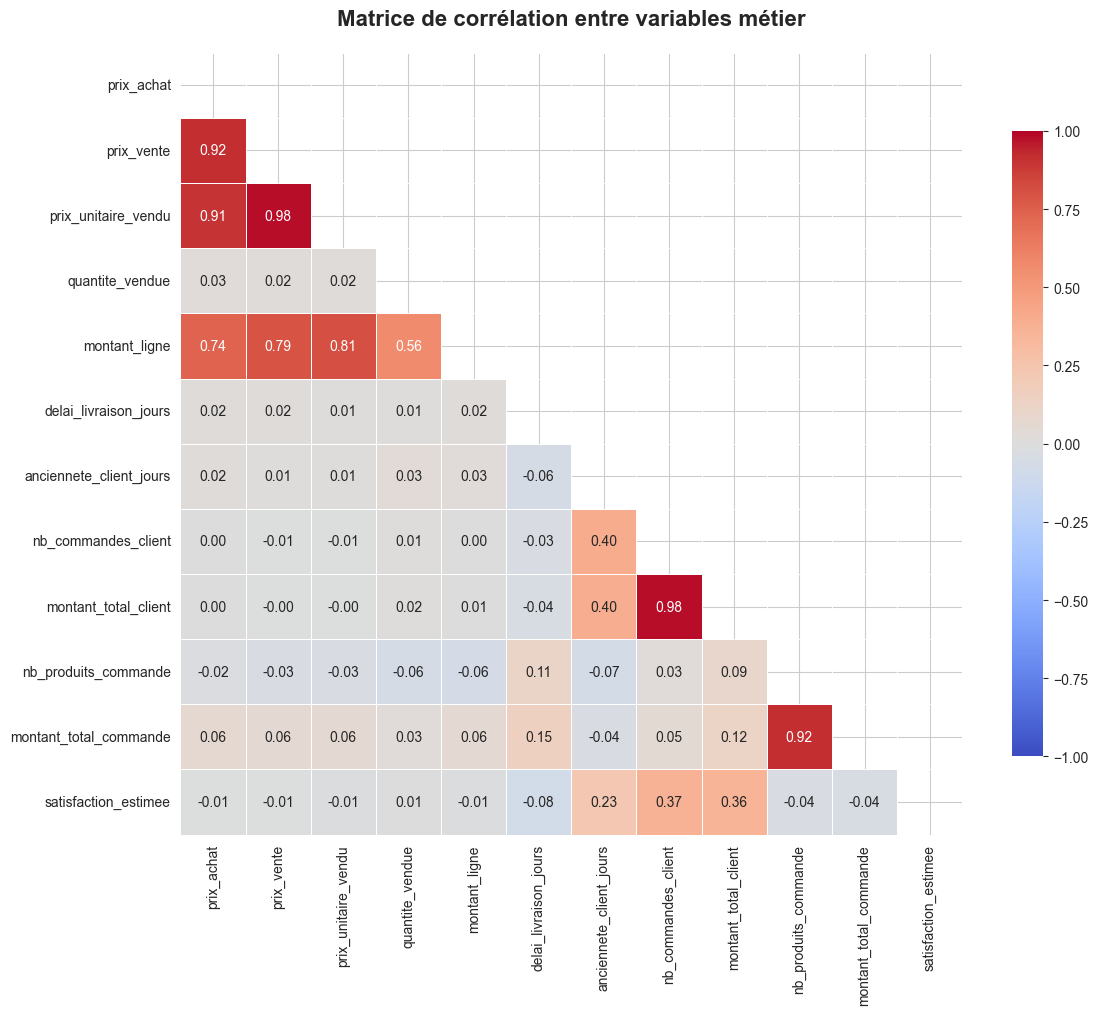

In [29]:
plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    vmin=-1,
    vmax=1
)

plt.title("Matrice de corrélation entre variables métier", fontsize=16, fontweight="bold", pad=20)
plt.tight_layout()
plt.show()

## Analyse des corrélations spécifiques

Analyse détaillée des corrélations les plus intéressantes.

In [30]:
# Corrélations les plus fortes (positives et négatives)
correlations_flat = correlation_matrix.unstack()
correlations_flat = correlations_flat[correlations_flat.index.get_level_values(0) != correlations_flat.index.get_level_values(1)]
correlations_flat = correlations_flat.sort_values(ascending=False)

print("Top 10 corrélations positives les plus fortes :")
print(correlations_flat.head(10))
print("\nTop 10 corrélations négatives les plus fortes :")
print(correlations_flat.tail(10))

Top 10 corrélations positives les plus fortes :
montant_total_client    nb_commandes_client       0.984182
nb_commandes_client     montant_total_client      0.984182
prix_unitaire_vendu     prix_vente                0.983111
prix_vente              prix_unitaire_vendu       0.983111
                        prix_achat                0.919214
prix_achat              prix_vente                0.919214
nb_produits_commande    montant_total_commande    0.915461
montant_total_commande  nb_produits_commande      0.915461
prix_achat              prix_unitaire_vendu       0.905219
prix_unitaire_vendu     prix_achat                0.905219
dtype: float64

Top 10 corrélations négatives les plus fortes :
anciennete_client_jours  delai_livraison_jours     -0.059468
delai_livraison_jours    anciennete_client_jours   -0.059468
quantite_vendue          nb_produits_commande      -0.060519
nb_produits_commande     quantite_vendue           -0.060519
                         montant_ligne             -0.

## Visualisations des corrélations spécifiques

Graphiques pour visualiser les relations entre variables clés.

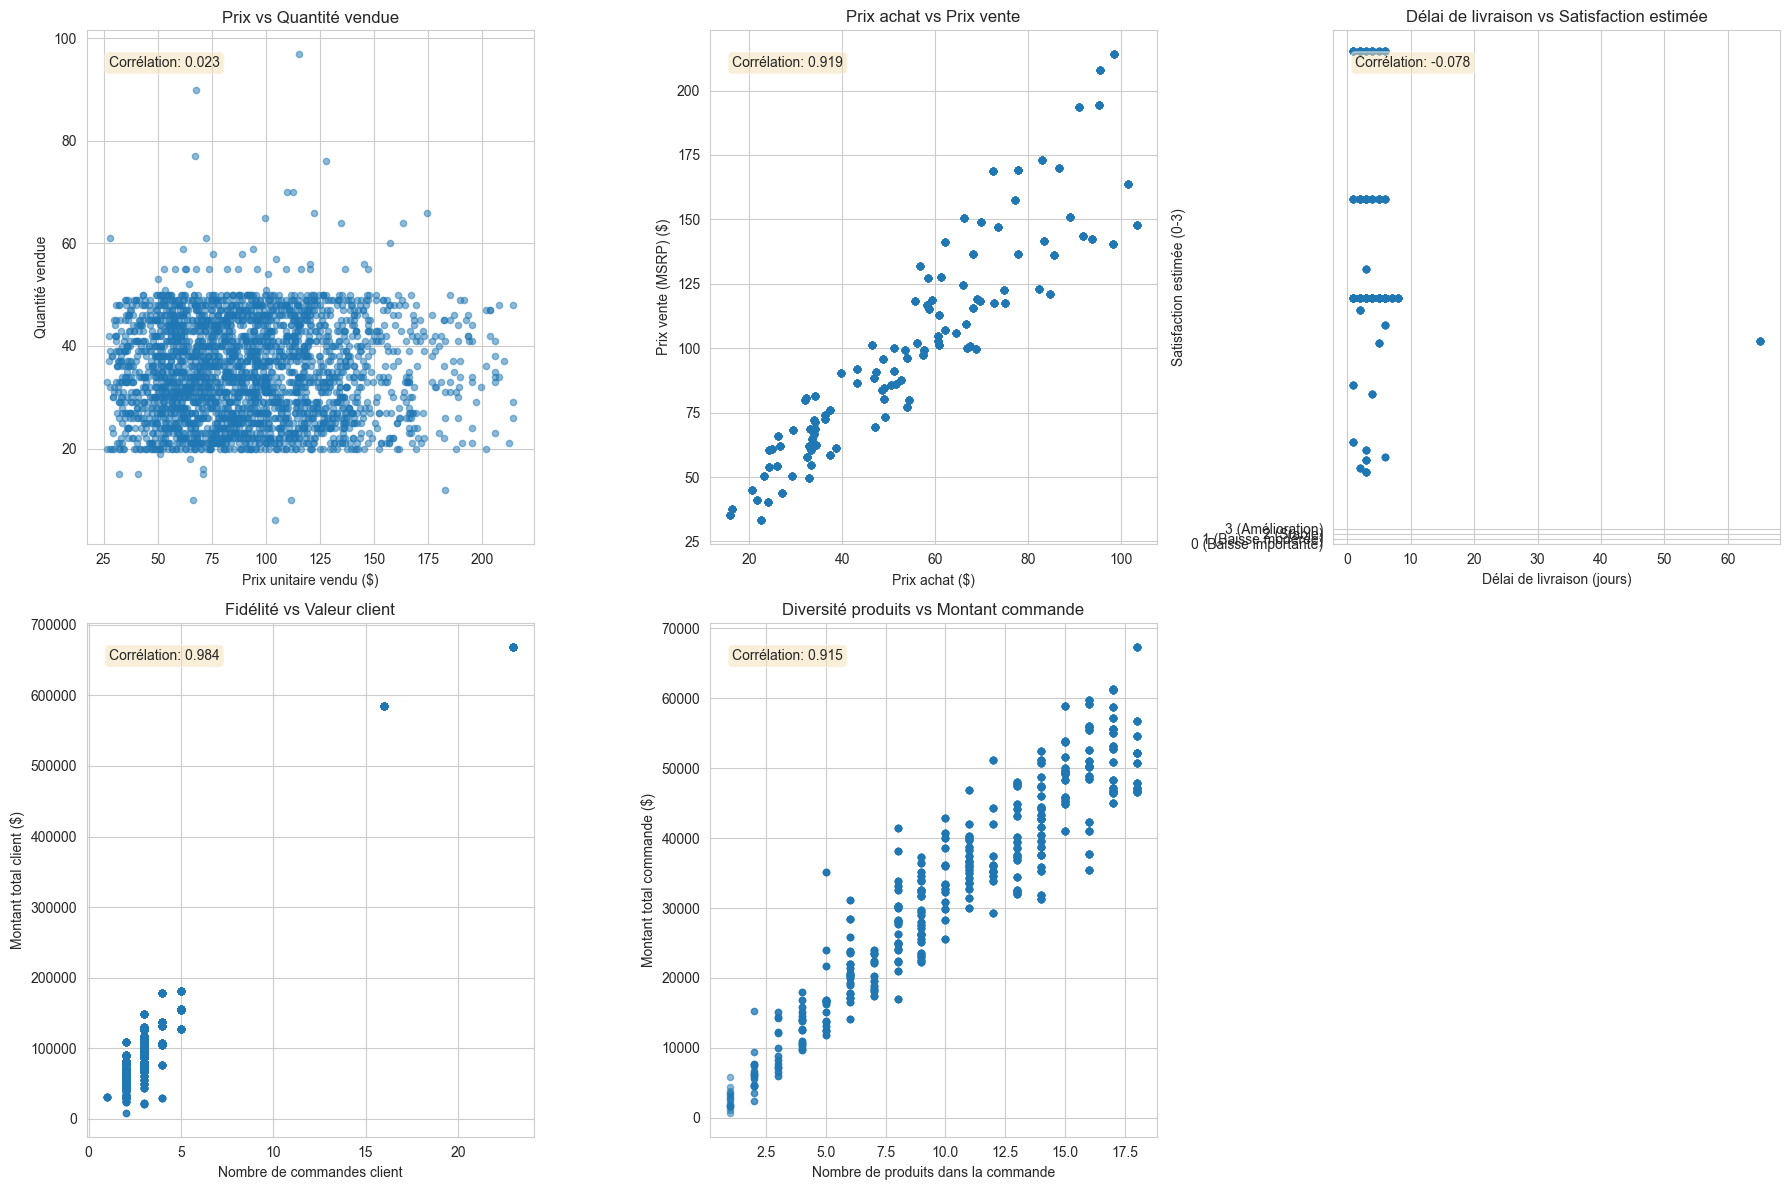

In [31]:
# Échantillonnage pour améliorer la performance des graphiques
df_sample = df_corr_numeric.sample(n=min(5000, len(df_corr_numeric)), random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Prix vs Quantité vendue
axes[0, 0].scatter(df_sample["prix_unitaire_vendu"], df_sample["quantite_vendue"], alpha=0.5, s=20)
axes[0, 0].set_xlabel("Prix unitaire vendu ($)")
axes[0, 0].set_ylabel("Quantité vendue")
axes[0, 0].set_title("Prix vs Quantité vendue")
corr_price_qty = df_corr_numeric["prix_unitaire_vendu"].corr(df_corr_numeric["quantite_vendue"])
axes[0, 0].text(0.05, 0.95, f"Corrélation: {corr_price_qty:.3f}", transform=axes[0, 0].transAxes, 
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 2. Prix achat vs Prix vente (marge)
axes[0, 1].scatter(df_sample["prix_achat"], df_sample["prix_vente"], alpha=0.5, s=20)
axes[0, 1].set_xlabel("Prix achat ($)")
axes[0, 1].set_ylabel("Prix vente (MSRP) ($)")
axes[0, 1].set_title("Prix achat vs Prix vente")
corr_buy_msrp = df_corr_numeric["prix_achat"].corr(df_corr_numeric["prix_vente"])
axes[0, 1].text(0.05, 0.95, f"Corrélation: {corr_buy_msrp:.3f}", transform=axes[0, 1].transAxes,
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 3. Délai de livraison vs Satisfaction estimée (utilise delai_livraison_jours)
axes[0, 2].scatter(df_sample["delai_livraison_jours"], df_sample["satisfaction_estimee"], alpha=0.5, s=20)
axes[0, 2].set_xlabel("Délai de livraison (jours)")
axes[0, 2].set_ylabel("Satisfaction estimée (0-3)")
axes[0, 2].set_title("Délai de livraison vs Satisfaction estimée")
axes[0, 2].set_yticks([0, 1, 2, 3])
axes[0, 2].set_yticklabels(["0 (Baisse importante)", "1 (Baisse modérée)", "2 (Stable)", "3 (Amélioration)"])
corr_delay_satisfaction = df_corr_numeric["delai_livraison_jours"].corr(df_corr_numeric["satisfaction_estimee"])
axes[0, 2].text(0.05, 0.95, f"Corrélation: {corr_delay_satisfaction:.3f}", transform=axes[0, 2].transAxes,
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 4. Nombre commandes vs Montant total client (fidélité)
axes[1, 0].scatter(df_sample["nb_commandes_client"], df_sample["montant_total_client"], alpha=0.5, s=20)
axes[1, 0].set_xlabel("Nombre de commandes client")
axes[1, 0].set_ylabel("Montant total client ($)")
axes[1, 0].set_title("Fidélité vs Valeur client")
corr_nb_orders_amount = df_corr_numeric["nb_commandes_client"].corr(df_corr_numeric["montant_total_client"])
axes[1, 0].text(0.05, 0.95, f"Corrélation: {corr_nb_orders_amount:.3f}", transform=axes[1, 0].transAxes,
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 5. Nombre produits vs Montant commande
axes[1, 1].scatter(df_sample["nb_produits_commande"], df_sample["montant_total_commande"], alpha=0.5, s=20)
axes[1, 1].set_xlabel("Nombre de produits dans la commande")
axes[1, 1].set_ylabel("Montant total commande ($)")
axes[1, 1].set_title("Diversité produits vs Montant commande")
corr_nb_amount = df_corr_numeric["nb_produits_commande"].corr(df_corr_numeric["montant_total_commande"])
axes[1, 1].text(0.05, 0.95, f"Corrélation: {corr_nb_amount:.3f}", transform=axes[1, 1].transAxes,
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Masquer le dernier subplot (vide)
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

## Interprétation détaillée des graphiques de corrélation

Analyse visuelle et interprétation métier de chaque relation identifiée.

### 1. Prix vs Quantité vendue (Corrélation : 0.023)

**Observation visuelle** : Les points sont dispersés de manière aléatoire, sans tendance claire. Aucune relation linéaire visible.

**Interprétation** :
- **Corrélation quasi-nulle (0.023)** : Le prix n'a pratiquement aucun impact sur les quantités vendues
- Les produits chers se vendent aussi bien que les produits bon marché
- Les clients achètent selon leurs besoins, pas selon le prix

**Implication métier** :
- **Opportunité stratégique majeure** : Le marché est non-élastique au prix
- Possibilité d'augmenter les prix pour maximiser les marges sans impact significatif sur les volumes
- Pas besoin de guerre des prix avec la concurrence
- Stratégie de prix premium viable

**Action recommandée** : Analyser les segments de produits pour identifier ceux où une augmentation de prix serait la plus rentable.


### 2. Prix achat vs Prix vente (Corrélation : 0.919)

**Observation visuelle** : Relation linéaire très forte et claire. Les points forment une ligne droite ascendante.

**Interprétation** :
- **Corrélation très forte (0.919)** : Le prix de vente (MSRP) est directement lié au coût d'achat
- La stratégie de tarification est cohérente et prévisible
- Les produits achetés plus cher sont vendus plus cher

**Implication métier** :
- La structure de prix est bien maîtrisée
- Pas de dumping ou de sur-marge excessive détectée
- La politique de marge est stable et cohérente

**Action recommandée** : Maintenir cette cohérence. Possibilité d'optimiser les marges sur les produits premium.

### 3. Délai de livraison vs Satisfaction estimée (Corrélation : -0.078)

**Observation visuelle** : 
- La plupart des points sont concentrés à des délais courts (0-10 jours) avec des scores de satisfaction variables
- Pour les délais plus longs (>20 jours), on observe une tendance à des scores de satisfaction plus faibles
- Distribution dispersée mais avec une légère tendance négative

**Interprétation** :
- **Corrélation négative faible (-0.078)** : Les délais longs ont un impact négatif léger mais détectable sur la satisfaction
- Les clients avec des délais courts (0-10 jours) ont des scores de satisfaction plus variés
- Les clients avec des délais très longs (>30 jours) tendent à avoir des scores plus faibles

**Implication métier** :
- **Impact détectable mais limité** : Les délais impactent la satisfaction, mais ce n'est pas le facteur principal
- La majorité des commandes ont des délais courts (0-10 jours), ce qui explique la concentration des points
- Les délais très longs sont rares mais impactent négativement la satisfaction

**Action recommandée** :
- Maintenir les délais courts pour la majorité des commandes (objectif <10 jours)
- Identifier et traiter les cas de délais exceptionnellement longs (>30 jours)
- Se concentrer aussi sur d'autres leviers de satisfaction (qualité, service client)

**Note méthodologique** : Le CSI (0-100) mesure l'évolution du comportement d'achat (panier moyen et fréquence sur 6 mois récents vs 6 mois précédents). Un score élevé indique une amélioration du comportement, un score faible indique une baisse.


### 4. Fidélité vs Valeur client (Corrélation : 0.984)

**Observation visuelle** : Relation linéaire exceptionnellement forte. Les points forment une ligne droite presque parfaite.

**Interprétation** :
- **Corrélation exceptionnelle (0.984)** : La fréquence d'achat est le facteur clé de la valeur client
- Un client qui commande 10 fois génère environ 10 fois plus de CA qu'un client qui commande 1 fois
- La relation est presque parfaitement proportionnelle

**Implication métier** :
- **INSIGHT LE PLUS IMPORTANT** : La fidélité (fréquence) est plus importante que le panier moyen
- Les programmes de fidélité visant à augmenter la fréquence d'achat sont prioritaires
- Un client fidèle vaut beaucoup plus qu'un client avec un gros panier unique

**Action recommandée** :
- **PRIORITÉ ABSOLUE** : Programmes de fidélité visant à augmenter la fréquence d'achat
- Campagnes marketing ciblées sur les clients à faible fréquence pour les réactiver
- Offres promotionnelles basées sur la fréquence (ex: "10ème commande gratuite")


### 5. Diversité produits vs Montant commande (Corrélation : 0.915)

**Observation visuelle** : Relation positive forte. Plus le nombre de produits augmente, plus le montant augmente, avec une variabilité croissante.

**Interprétation** :
- **Corrélation forte (0.915)** : Chaque produit supplémentaire dans le panier augmente significativement le CA
- La diversité du panier est un levier puissant pour augmenter le CA par transaction
- La variabilité augmente avec le nombre de produits (certains clients achètent beaucoup, d'autres moins)

**Implication métier** :
- **Cross-sell très efficace** : Les stratégies de recommandation de produits complémentaires fonctionnent
- Ajouter des produits au panier augmente fortement le CA
- Les clients qui diversifient dépensent beaucoup plus

**Action recommandée** :
- **Stratégies de cross-sell agressives** : "Les clients ayant acheté X ont aussi acheté Y"
- Suggestions de produits complémentaires sur le site/point de vente
- Offres groupées : Packs de produits à prix réduit pour inciter à la diversité
- Formation des commerciaux sur les techniques de cross-sell